# Auscultation AI: reproduce the results

AI analysis of heart and lung stethoscope sounds, trained only on public data. This notebook downloads the published models, re-runs the check on all 34 held-out test recordings, shows the held-out metrics, and lets you analyse a recording of your own.

**Research prototype. Decision support only. Not a medical device.**

- Live app: https://auscultation-ai.vercel.app
- Code: https://github.com/adityavdn/auscultation-ai
- Report (IEEE format): https://github.com/adityavdn/auscultation-ai/blob/main/docs/report/report.pdf

Run the cells in order (Runtime → Run all). It takes about two minutes on a free CPU runtime; no GPU or account keys are needed.

## 1. Get the code and the trained models
The models come from the repository's `v5` release and are checked against a pinned SHA-256 before use (joblib files are pickles).

In [1]:
!git clone -q --depth 1 https://github.com/adityavdn/auscultation-ai.git
%cd auscultation-ai
%pip install -q -r requirements.txt
!curl -fsSL -o assets.tgz https://github.com/adityavdn/auscultation-ai/releases/download/v5/auscultation-assets.tgz
!echo "a2a1c3ac022ed48fbcb1c470d45e9276bff4287078f1ec88e9793ab0a594ccac  assets.tgz" | sha256sum -c - && tar xzf assets.tgz && ls models samples | head

## 2. Held-out results
Test sets are split by patient wherever the dataset publishes patient IDs. Published figures elsewhere use other test sets, so compare with care.

In [2]:
import json
import pandas as pd

metrics = json.load(open("metrics.json"))
rows = []
for task, r in metrics.items():
    if not isinstance(r, dict) or "accuracy" not in r:
        continue
    if "macc" in r:
        metric, score = "MAcc", r["macc"]
    elif "icbhi" in r:
        metric, score = "ICBHI score", r["icbhi"]["score"]
    elif task == "lung_diagnosis":  # ~86% COPD, so accuracy would mostly measure COPD
        metric, score = "macro-F1", r["macro_f1"]
    else:
        metric, score = "accuracy", r["accuracy"]
    rows.append({"task": task, "metric": metric, "score": round(score, 3), "macro-F1": round(r["macro_f1"], 3),
                 "test recordings": r.get("n_test_rec"), "test patients": r.get("n_test_patients")})
pd.DataFrame(rows)

,task,metric,score,macro-F1,test recordings,test patients
0,heart_abnormal,MAcc,0.882,0.810,648,648
1,heart_murmur,MAcc,0.724,0.689,602,175
2,heart_valve,accuracy,1.000,1.000,200,200
3,lung_sound,ICBHI score,0.507,0.370,2756,49
4,lung_diagnosis,macro-F1,0.433,0.433,252,49


## 3. Re-run the live check on the 34 held-out samples
Each recording goes through the same pipeline as the web app: quality checks, the stethoscope-or-not gate, windowing, and the model heads.

In [3]:
from app.inference import Analyzer

analyzer = Analyzer("models")
manifest = json.load(open("samples/manifest.json"))
rows = []
for s in manifest:
    result = analyzer.analyze(open(f"samples/{s['file']}", "rb").read(), s["kind"])
    head = result["heads"][s["task"]]
    rows.append({"task": s["task"], "dataset": s["dataset"], "true label": s["true_label"],
                 "predicted": head["label"], "confidence": round(head["confidence"], 2),
                 "match": head["label"] == s["true_label"]})
check = pd.DataFrame(rows)
print(f"{check.match.sum()} of {len(check)} samples match their dataset label")
check.groupby("task").match.agg(["sum", "count"])

32 of 34 samples match their dataset label


,sum,count
task,,
heart_abnormal,4,4
heart_murmur,3,4
heart_valve,7,7
lung_diagnosis,18,19


In [4]:
check

,task,dataset,true label,predicted,confidence,match
0,heart_abnormal,cinc2016,abnormal,abnormal,0.81,True
1,heart_abnormal,cinc2016,abnormal,abnormal,0.64,True
2,heart_abnormal,cinc2016,normal,normal,0.85,True
3,heart_abnormal,cinc2016,normal,normal,0.87,True
4,heart_murmur,circor,absent,absent,0.88,True
5,heart_murmur,circor,absent,absent,0.89,True
6,heart_murmur,circor,present,present,0.40,True
7,heart_murmur,circor,present,absent,0.88,False
8,heart_valve,yaseen,AS,AS,1.00,True
9,heart_valve,yaseen,AS,AS,1.00,True


## 4. One combined heart + lung report
The fusion layer merges both organs into one status and adds cross-system flags.

{
  "status": "abnormal",
  "flags": [],
  "summary": "heart abnormal: abnormal (81%); heart murmur: absent (97%); heart valve: normal (66%); lung diagnosis: asthma (100%); lung sound: normal (96%)"
}


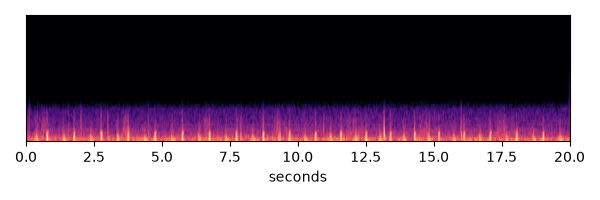

In [5]:
import base64
from IPython.display import Audio, Image, display
from app.fusion import fuse

heart = next(s for s in manifest if s["kind"] == "heart" and s["true_label"] == "abnormal")
lung = next(s for s in manifest if s["kind"] == "lung")
h = analyzer.analyze(open(f"samples/{heart['file']}", "rb").read(), "heart")
l = analyzer.analyze(open(f"samples/{lung['file']}", "rb").read(), "lung")
print(json.dumps(fuse(h["heads"], l["heads"]), indent=2))
display(Image(data=base64.b64decode(h["spectrogram_png_b64"])), Audio(f"samples/{heart['file']}"))

## 5. Try your own recording (optional)
Upload a heart or lung recording (wav, mp3, m4a). Set `KIND` to `"heart"` or `"lung"`. Audio that does not sound like a stethoscope is rejected with a reason.

In [ ]:
KIND = "heart"
try:
    from google.colab import files
    uploaded = files.upload()
    for name, data in uploaded.items():
        r = analyzer.analyze(data, KIND)
        print(name, {k: (v["label"], round(v["confidence"], 2)) for k, v in r["heads"].items()})
except ImportError:
    print("Uploading works inside Google Colab; elsewhere call analyzer.analyze(open(path, 'rb').read(), KIND).")
except Exception as e:
    print("Could not analyse:", e)